# Inferring Genealogies in Small Sequence Controls

Which ancestors can explain a small sequence sample?
Use four labeled copies from the nonrecombining control, then four copies from a linked
control. These controls are separate from the main forward population.
The saved data and plots identify them as D3 R1 and D4.
Keep these samples and windows fixed before opening any ancestry record.
Shared derived alleles constrain branches. Their counts, with a supplied mutation rate,
contain information about elapsed generations.


In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 4.5, repr.plot.pointsize = 13,
        repr.plot.bg = "white", warn = 1)
blue <- "#265991"; orange <- "#D65F22"
drawFigure <- function(name, draw, width = 9, height = 3.6) {
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height,
            family = "Helvetica", pointsize = 13, useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


In [2]:
observed <- (function() {
  payload <- as.raw(c(
    31,139,8,0,0,0,0,0,0,3,237,90,11,80,83,87,26,190,225,33,143,128,107,17,90,87,121,180,234,80,
    138,157,106,2,136,143,181,156,90,192,170,197,117,4,186,138,15,30,18,32,211,16,35,9,145,32,58,9,144,64,
    0,161,182,174,14,35,181,181,142,69,214,173,211,93,106,91,11,69,96,215,186,157,186,221,90,237,84,4,199,245,
    209,238,206,226,128,56,44,118,107,173,251,31,76,238,197,112,239,205,189,55,1,162,211,51,147,124,255,249,207,127,
    254,243,223,123,207,255,56,55,89,235,75,16,132,27,225,225,233,78,184,185,99,114,42,124,121,88,16,51,166,192,
    199,15,56,62,120,48,89,66,82,82,146,138,34,169,104,146,138,33,169,249,36,21,75,82,11,72,106,161,133,114,
    79,150,204,163,72,9,69,74,1,38,195,71,68,80,205,98,154,213,212,97,19,69,86,149,107,36,214,25,168,14,
    89,103,224,190,23,66,159,69,188,15,4,218,166,40,110,91,3,104,200,75,126,234,96,59,160,185,94,51,23,250,
    149,177,157,159,191,12,88,115,246,219,94,49,240,119,253,148,127,247,59,61,86,234,15,95,41,4,183,38,178,161,
    69,76,130,60,229,216,198,133,172,57,214,250,109,229,68,163,121,30,110,4,245,228,220,179,229,249,0,248,86,99,
    182,31,124,188,108,68,188,65,68,153,153,47,83,19,247,55,1,30,155,66,76,248,254,156,50,108,170,101,138,150,
    52,65,75,154,160,37,77,208,146,38,104,73,19,180,164,9,218,88,248,254,217,230,162,61,173,87,140,151,241,176,
    48,125,10,100,185,242,45,202,116,121,182,133,17,144,169,204,84,232,138,101,217,233,10,153,50,87,147,151,158,165,
    178,140,248,169,182,168,229,26,16,86,83,60,223,188,76,149,98,139,70,167,26,86,252,51,163,47,145,222,103,227,
    75,129,40,33,169,43,238,60,248,74,206,250,247,18,63,6,148,239,15,191,216,9,168,46,152,222,253,19,160,214,
    255,173,176,64,236,107,185,203,55,33,61,129,116,125,95,28,186,8,184,61,234,249,157,39,1,75,250,247,5,237,
    131,241,29,27,149,254,135,1,119,150,4,45,91,15,124,253,228,12,205,32,2,140,108,221,24,3,125,211,178,143,
    78,174,128,126,69,89,241,151,55,192,39,43,67,197,179,110,3,223,60,16,88,31,134,125,53,253,153,148,15,176,
    175,206,255,251,147,231,64,174,214,184,185,211,171,157,176,248,236,77,150,253,56,146,207,117,223,138,24,120,124,228,
    199,218,30,38,61,92,248,92,236,177,229,217,91,135,139,29,246,100,185,206,183,210,116,250,28,181,135,207,253,25,
    75,121,87,180,127,12,239,63,142,133,162,123,196,131,137,33,240,62,223,13,243,93,44,17,4,58,41,17,88,41,
    210,4,45,105,130,150,50,65,75,153,160,149,72,41,50,138,34,163,41,50,134,34,231,83,100,44,69,46,160,72,
    106,53,233,60,130,204,74,238,247,136,9,73,68,81,4,125,34,242,65,41,93,27,166,225,132,179,174,105,86,30,
    78,72,121,51,253,206,4,225,132,228,209,221,29,14,168,106,201,35,238,2,110,125,78,157,254,18,160,177,175,77,
    124,7,39,20,115,211,198,221,144,72,118,205,92,144,93,167,39,44,9,67,193,176,57,153,26,219,166,230,234,88,
    76,58,232,130,58,87,123,108,215,97,75,20,92,245,177,241,236,205,23,162,135,45,144,216,20,145,163,2,132,143,
    235,6,8,159,49,12,16,227,231,167,15,44,226,110,149,82,103,230,171,20,50,88,68,109,225,248,15,115,228,202,
    220,116,141,60,95,102,97,122,221,183,101,164,199,63,82,39,205,16,20,121,124,243,143,175,65,176,137,159,59,179,
    21,159,40,179,31,251,189,73,141,131,210,172,230,68,8,101,168,224,219,233,193,160,23,105,58,245,103,119,66,16,
    218,150,218,235,25,2,88,164,10,107,90,1,252,162,166,37,193,105,208,223,158,168,91,250,25,96,201,59,111,85,
    201,49,126,158,177,61,7,198,75,46,53,72,244,208,55,4,205,62,252,58,244,13,43,103,168,255,5,88,218,48,
    120,217,23,130,91,217,179,225,65,122,232,151,117,76,59,213,219,78,160,242,245,175,28,191,133,131,159,255,157,234,
    21,208,55,182,246,247,169,0,43,229,203,51,190,7,52,167,4,44,237,128,121,230,3,171,77,157,128,85,215,63,
    205,107,3,253,213,65,102,175,19,56,72,106,154,219,182,129,220,174,255,157,159,236,3,88,231,31,218,176,3,95,
    46,14,154,162,13,4,125,227,115,162,180,39,207,101,190,149,230,26,96,233,116,178,5,28,182,224,233,108,123,28,
    189,63,116,122,232,198,132,36,2,161,246,59,210,184,158,110,184,232,225,43,55,22,207,203,89,251,147,110,111,186,
    226,126,27,111,127,180,103,15,147,126,62,247,211,158,237,182,180,35,126,192,165,232,9,113,221,162,39,228,81,60,
    21,145,36,181,154,148,90,77,74,173,38,165,86,147,82,171,73,169,213,164,212,106,82,106,53,233,120,22,116,60,
    223,0,78,69,47,73,79,158,59,3,53,69,150,108,247,19,63,0,230,150,4,255,229,123,64,69,203,190,197,161,
    128,249,67,247,18,150,224,90,103,40,34,52,23,215,54,203,62,94,180,23,176,184,80,254,205,108,192,157,51,38,
    249,158,6,212,103,61,245,222,135,128,165,191,238,115,123,27,106,139,178,213,254,147,186,96,158,233,104,101,181,9,
    248,166,191,205,137,89,133,107,146,230,85,119,123,0,171,187,150,213,124,5,114,213,151,255,243,167,119,97,188,230,
    52,113,105,29,96,237,127,139,214,94,195,230,13,31,228,174,143,246,153,7,124,105,164,79,177,197,16,33,249,211,
    158,126,190,241,96,172,242,255,72,25,190,49,206,118,92,72,94,21,210,152,238,55,31,251,199,74,222,145,253,32,
    212,30,161,123,137,107,227,187,15,88,26,109,206,154,234,186,57,107,234,35,147,179,38,60,139,48,189,190,11,136,
    251,231,234,170,87,128,64,146,199,7,123,84,128,113,135,110,204,193,184,54,35,171,225,175,128,27,99,59,250,222,
    6,204,57,245,155,254,13,56,203,236,62,246,198,85,192,87,159,254,227,0,30,47,80,232,234,74,49,94,63,151,
    216,3,89,96,199,34,69,244,143,56,171,20,230,36,253,1,176,44,45,184,123,55,100,141,242,5,169,215,90,64,
    174,252,221,189,231,3,33,123,24,211,14,54,38,1,223,52,163,245,31,253,208,55,61,221,120,163,18,155,53,156,
    61,46,216,217,202,206,246,34,62,115,248,86,159,92,215,18,114,186,114,198,201,206,158,62,71,170,109,190,167,17,
    166,123,192,22,109,233,228,232,198,184,200,179,53,62,247,154,203,137,200,222,245,10,93,131,163,126,218,108,16,224,
    186,217,32,224,225,206,6,191,188,25,118,108,11,56,231,205,176,47,74,85,127,114,181,22,242,144,82,252,221,145,
    66,64,117,115,253,222,1,200,83,133,141,3,241,248,141,176,118,107,87,90,46,96,197,98,227,237,155,192,55,199,
    63,239,85,5,125,243,111,231,100,226,255,79,84,125,81,118,238,69,200,87,181,183,181,131,231,177,238,225,124,85,
    68,140,246,59,46,31,103,52,174,121,138,235,9,136,79,21,108,69,190,215,202,102,11,215,188,225,76,123,236,233,
    38,24,226,165,175,235,198,75,223,241,137,151,19,94,218,50,189,32,17,163,172,57,155,74,123,112,105,122,185,126,
    29,254,101,186,120,240,125,77,60,160,190,51,231,184,17,74,79,131,52,100,17,254,11,148,161,38,93,42,3,151,
    46,189,40,77,88,136,75,214,3,71,18,127,192,37,106,109,56,154,2,114,149,189,186,43,133,56,20,156,238,61,
    232,166,39,44,46,95,78,179,109,248,186,56,215,82,132,203,97,212,81,253,246,198,152,66,134,51,66,25,91,120,
    112,180,141,87,41,205,84,82,137,93,55,68,136,199,189,164,154,240,104,193,116,16,246,70,17,237,123,174,222,132,
    104,176,222,175,102,241,227,128,155,39,249,189,224,13,248,234,149,47,141,248,143,149,74,195,133,196,19,128,91,15,
    94,187,125,8,176,48,109,104,229,21,136,10,21,141,232,43,79,61,97,137,10,25,252,118,140,211,100,28,217,189,
    92,146,243,72,154,75,84,19,82,148,56,163,49,121,161,183,235,122,161,183,211,189,240,151,179,134,99,79,133,238,
    172,33,226,125,214,8,70,201,175,31,56,112,214,16,140,126,39,249,243,145,232,12,15,148,190,221,51,225,68,127,
    37,218,252,68,220,180,170,43,151,144,44,101,82,249,11,171,10,145,242,112,68,241,158,79,18,208,86,221,190,111,
    94,251,213,113,84,208,97,218,223,94,30,128,212,111,180,132,12,61,155,138,182,205,206,141,186,113,43,14,233,60,
    235,155,50,239,118,162,226,83,95,159,169,143,236,69,37,199,204,183,238,45,157,142,244,109,151,30,91,25,59,132,
    12,207,173,148,204,219,99,64,134,36,34,187,161,39,18,149,134,39,133,245,138,215,160,178,127,47,239,216,114,97,
    15,42,159,177,162,62,114,127,55,50,102,183,108,152,155,60,27,25,101,254,57,226,99,205,200,120,244,101,217,194,
    229,74,84,241,76,68,222,146,184,2,84,241,117,108,73,234,155,58,84,21,170,240,136,73,110,68,213,173,97,245,
    11,59,148,104,215,157,185,157,71,221,114,81,221,147,69,3,155,130,231,223,15,121,162,213,220,220,114,20,205,86,
    175,19,52,52,223,102,175,246,23,26,54,133,204,19,34,47,180,112,17,114,238,225,114,94,179,119,190,18,98,59,
    157,45,108,99,92,11,93,103,173,203,215,30,103,92,55,219,51,26,73,179,221,127,174,107,177,141,59,226,31,66,
    199,248,220,79,186,248,64,23,47,152,124,159,173,49,61,3,46,205,222,117,208,140,211,150,44,193,174,91,178,4,
    143,251,193,129,36,31,190,127,147,60,140,213,24,173,185,110,241,228,211,142,39,159,118,60,249,180,227,163,241,220,
    255,3,7,24,94,74,208,58,0,0
  ))
  con <- gzcon(rawConnection(payload))
  on.exit(close(con))
  readRDS(con)
})()

calibration <- (function() {
  payload <- as.raw(c(
    31,139,8,0,0,0,0,0,0,3,237,82,189,78,195,48,16,78,147,84,85,139,168,128,110,12,149,95,0,169,
    64,55,36,88,88,145,96,99,139,220,228,154,156,20,255,200,118,4,47,128,196,83,240,22,72,188,15,35,19,18,
    3,19,96,167,110,40,145,152,96,76,36,251,206,223,221,247,229,156,124,215,163,32,8,194,32,238,71,65,24,185,
    116,98,183,216,199,129,93,99,187,122,167,111,239,143,247,207,197,171,63,187,198,223,158,29,215,111,21,134,54,206,
    82,193,13,242,74,84,250,64,10,141,6,5,39,200,151,200,209,0,177,103,208,39,68,9,97,136,54,212,34,179,
    22,127,142,152,145,138,227,82,40,70,164,16,37,100,68,82,5,220,208,146,164,66,162,227,95,10,212,218,234,234,
    27,52,105,1,218,242,70,181,198,106,109,234,77,151,120,107,37,74,186,128,210,105,25,80,12,121,163,229,111,29,
    181,88,253,5,213,181,236,38,56,184,16,42,167,188,13,111,229,192,65,81,119,81,91,138,195,77,25,78,89,35,
    19,121,112,184,254,44,218,3,17,163,210,167,177,65,6,54,126,172,132,122,159,158,59,240,245,125,86,37,18,84,
    226,198,171,147,239,119,251,142,61,43,150,148,192,115,83,232,132,213,3,251,202,152,85,166,238,180,112,6,165,71,
    119,145,23,160,208,80,158,194,143,194,68,65,238,134,76,144,103,32,193,110,220,248,210,182,166,76,150,144,100,160,
    49,95,203,247,237,79,51,122,53,123,231,164,127,114,82,99,128,206,60,157,121,58,243,252,209,60,189,179,135,167,
    171,151,187,233,83,103,150,206,44,237,217,99,223,16,158,31,54,217,81,147,29,55,217,220,113,191,0,213,214,244,
    25,67,9,0,0
  ))
  con <- gzcon(rawConnection(payload))
  on.exit(close(con))
  readRDS(con)
})()


## Which branches do the observed alleles support?

Rows are copies S1–S4. Columns are observed sites, with 0 ancestral and 1 derived.
The supplied analyzed length is 1,000 bases, including sites where these copies agree.
The calibrated mutation rate is $\mu=2\times10^{-5}$ per base per generation.
For the nonrecombining control, remove columns fixed within these four copies when
finding branches, while retaining the full analyzed length for the mutation clock.

Under error-free infinite sites, each derived-carrier set must be a clade.
Enumerate all 15 rooted binary trees on four labels and retain every compatible tree.
An unsupported split remains unresolved in the displayed consensus.


In [3]:
samples <- 1:4
r1 <- observed$D3$regions[[1]]
mu <- calibration$D3$mu_per_base_per_generation
L <- r1$analyzed_length_bp
G3 <- r1$haplotypes[samples, , drop = FALSE]
consensus3 <- ptiConsensus(G3)
keep3 <- colSums(G3) > 0 & colSums(G3) < 4
print(list(variable_sites = sum(keep3), supported_clades = consensus3$supported_clades,
           compatible_binary_trees = consensus3$compatible_count))


$variable_sites
[1] 7

$supported_clades
$supported_clades[[1]]
[1] 1 3 4


$compatible_binary_trees
[1] 3



In [4]:
cladeNodes <- function(tree) {
    clades <- ptiTreeClades(tree)
    keys <- vapply(clades, ptiKey, character(1))
    root <- ptiKey(sort(as.integer(unlist(tree))))
    parent <- setNames(rep(NA_character_, length(keys)), keys)
    for (key in setdiff(keys, root)) {
        child <- clades[[match(key, keys)]]
        larger <- Filter(function(x) length(x) > length(child) && all(child %in% x), clades)
        parent[key] <- ptiKey(larger[[which.min(lengths(larger))]])
    }
    list(clades = clades, keys = keys, parent = parent, root = root)
}
drawTree <- function(tree, ages = NULL, maximum = NULL, title = "") {
    nodes <- cladeNodes(tree)
    order <- as.integer(unlist(tree))
    x <- setNames(vapply(nodes$clades, function(c) mean(match(c, order)), numeric(1)),
                  nodes$keys)
    if (is.null(ages)) {
        ages <- setNames(lengths(nodes$clades) - 1, nodes$keys)
        y_label <- ""
    } else {
        ages <- c(setNames(rep(0, 4), as.character(1:4)), ages)
        y_label <- "Generations before sampling"
    }
    if (is.null(maximum)) maximum <- max(ages) * 1.18
    plot(NA, xlim = c(.6, 4.4), ylim = c(0, max(1, maximum)),
         xaxt = "n", yaxt = if (nzchar(y_label)) "s" else "n", bty = "n",
         xlab = "", ylab = y_label, main = title)
    axis(1, 1:4, paste0("S", order), tick = FALSE)
    for (key in setdiff(nodes$keys, nodes$root)) {
        parent <- nodes$parent[key]
        segments(x[key], ages[key], x[key], ages[parent], lwd = 2, col = blue)
        segments(x[key], ages[parent], x[parent], ages[parent], lwd = 2, col = blue)
    }
}
drawCarriers <- function(G, positions = NULL, key = FALSE) {
    keep <- colSums(G) > 0 & colSums(G) < nrow(G)
    G <- G[, keep, drop = FALSE]
    if (is.null(positions)) positions <- seq_len(ncol(G)) else positions <- positions[keep]
    plot(NA, xlim = range(c(positions, 0)), ylim = c(.6, if (key) 5.5 else 4.4), yaxt = "n",
         xlab = if (max(positions) > 30) "Position (bases)" else "Variable site",
         ylab = "", bty = "n")
    axis(2, 4:1, paste0("S", 1:4), las = 1, tick = FALSE)
    for (i in 1:4) {
        points(positions, rep(5-i, length(positions)), pch = ifelse(G[i, ] == 1, 16, 1),
               col = ifelse(G[i, ] == 1, blue, "gray65"), cex = 1.15)
    }
    if (key) legend("topright", c("Derived", "Ancestral"), pch = c(16, 1),
                    col = c(blue, "gray65"), bty = "n", ncol = 2, cex = .85)
}


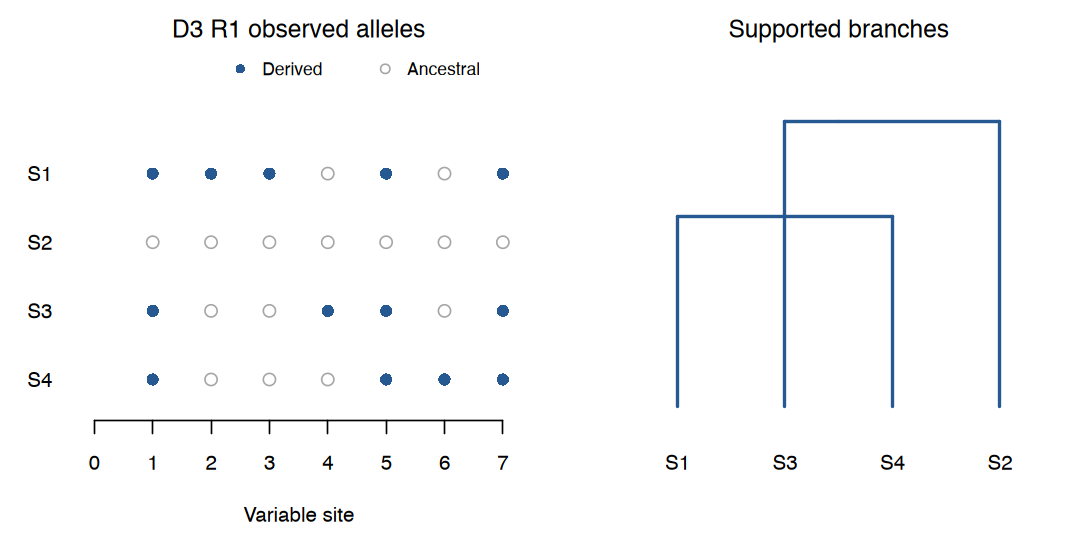

In [5]:
drawFigure("p6_supported_clades", function() {
    par(mfrow = c(1, 2), mar = c(4.6, 3, 2.2, .8), bg = "white")
    drawCarriers(G3, key = TRUE)
    title("D3 R1 observed alleles")
    drawTree(consensus3$tree, title = "Supported branches")
})


## Estimate elapsed time using the mutation model

For branch $b$, let $t_b$ be its length in generations and $M_b$ its mutation count.
Conditional on a compatible topology, $M_b\sim\operatorname{Poisson}(\mu L t_b)$
independently across branches. Fit nonnegative time intervals, keeping all tied optima.

Here C={S1,S3,S4} has four terminal mutations in total and three on its shared branch.
Write $a$ for C's ancestor age and $w$ for the time from that ancestor to the root.
S2 has no terminal mutation. The collapsed-tree likelihood is proportional to
$a^4w^3\exp\{-\mu L(4a+2w)\}$. It predicts $\hat a=50$, $\hat w=75$ and
root age 125 generations. Every compatible binary refinement has the same optimum
with its unsupported internal edge at zero. That boundary fit leaves the split unresolved.

For a fixed pair, $D_{ij}\mid T_{ij}\sim\operatorname{Poisson}(2\mu LT_{ij})$.
Use exact Poisson intervals, adjusted over all six predeclared pairs. Because
$T_{\rm MRCA}(C)=\max_{i<j\in C}T_{ij}$, maxima of the lower and upper endpoints
give conservative simultaneous 95% intervals for the root and supported clade ages.
The pair counts share branches, so they are dependent; the simultaneous guarantee
uses the union bound, not an independence assumption.


In [6]:
fit3 <- ptiFitAges(G3, mu, L)
pairs3 <- ptiPairIntervals(G3, mu, L)
intervals3 <- lapply(fit3$node_ages$clade, function(key)
    ptiCladeInterval(pairs3, as.integer(strsplit(key, ",", fixed = TRUE)[[1]])))
age_table <- fit3$node_ages
age_table$lower <- vapply(intervals3, `[[`, numeric(1), "lower")
age_table$upper <- vapply(intervals3, `[[`, numeric(1), "upper")
print(age_table, row.names = FALSE)
stopifnot(abs(age_table$estimate_min[age_table$clade == "1,3,4"] - 50) < 1e-4,
          abs(age_table$estimate_min[age_table$clade == "1,2,3,4"] - 125) < 1e-4)
frozen_inference <- serialize(list(consensus3, fit3, pairs3, intervals3), NULL)


   clade estimate_min estimate_max same_height_across_best_fits    lower    upper
   1,3,4           50           50                         TRUE  7.90644 280.4692
 1,2,3,4          125          125                         TRUE 25.78864 360.4523


## Where do the observed carriers require a change of tree?

The linked control is a separate simulated sample. Keep the first four labels and inspect
four quarters fixed by position. A compatible window may still contain hidden tree changes.
Two carrier sets that overlap without either containing the other cannot both be
clades of one rooted tree under error-free infinite sites.

Find the fewest contiguous compatible blocks across the observed sites, retaining all
equally minimal partitions. These are constraints on necessary changes. Their allowed
cut gaps are compatibility ranges, not confidence intervals or a reconstruction of every event.
We do not assign single-tree clock intervals to these linked windows.


In [7]:
linked <- observed$D4$regions[[1]]
G4 <- linked$haplotypes[samples, , drop = FALSE]
positions4 <- linked$positions_bp
constraints4 <- ptiLinkedConstraints(G4, positions4)
quarters <- seq(0, linked$analyzed_length_bp, length.out = 5)
local_consensus <- lapply(1:4, function(i) ptiConsensus(G4[, positions4 >= quarters[i] &
    positions4 < quarters[i+1], drop = FALSE]))
print(data.frame(quarter = 1:4, compatible_trees =
    vapply(local_consensus, `[[`, integer(1), "compatible_count")))
print(list(minimum_blocks = constraints4$minimum_blocks,
           equally_minimal_partitions = length(constraints4$minimal_cut_sets)))
frozen_linked <- serialize(list(constraints4, local_consensus), NULL)


  quarter compatible_trees
1       1                1
2       2                1
3       3                3
4       4                3


$minimum_blocks
[1] 3

$equally_minimal_partitions
[1] 12



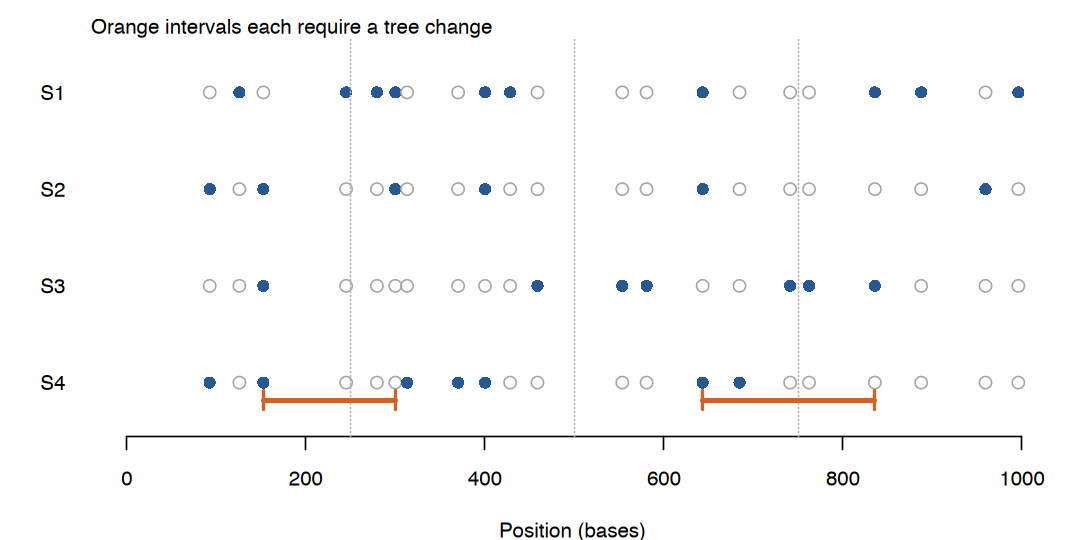

In [8]:
drawFigure("p6_linked_carriers", function() {
    par(mar = c(4, 3.5, 1.5, 1), bg = "white")
    drawCarriers(G4, positions4)
    abline(v = quarters[2:4], lty = 3, col = "gray70")
    w <- constraints4$disjoint_witnesses
    for (i in seq_len(nrow(w))) {
        segments(w$left[i], .82, w$right[i], .82, col = orange, lwd = 3)
        segments(c(w$left[i], w$right[i]), .72, c(w$left[i], w$right[i]), .92,
                 col = orange, lwd = 2)
    }
    mtext("Orange intervals each require a tree change", 3, line = .1, adj = 0)
})


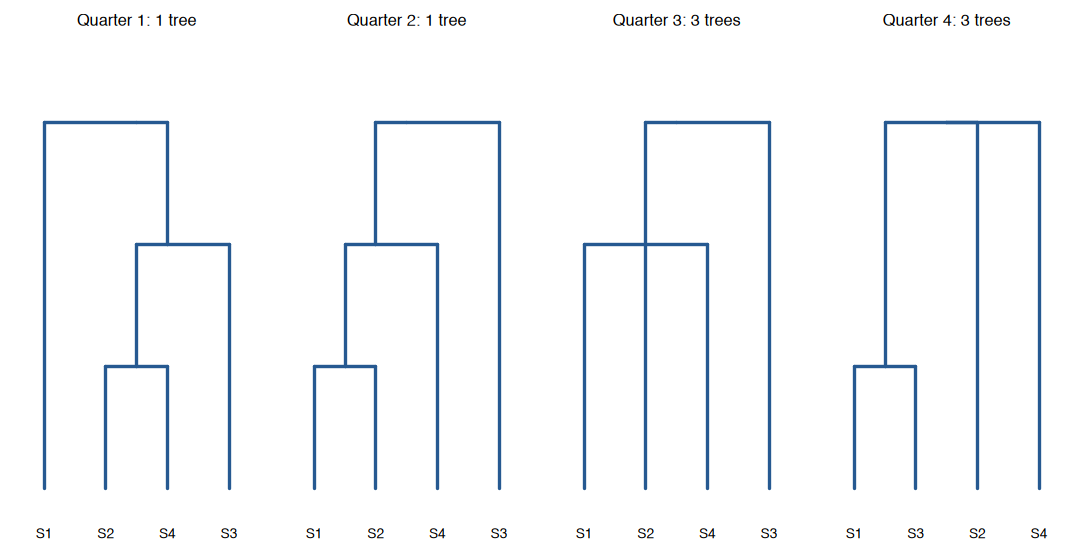

In [9]:
drawFigure("p6_local_constraints", function() {
    par(mfrow = c(1, 4), mar = c(2, .6, 2.3, .4), bg = "white")
    for (i in 1:4) drawTree(local_consensus[[i]]$tree,
        title = paste0("Quarter ", i, ": ", local_consensus[[i]]$compatible_count,
                       if (local_consensus[[i]]$compatible_count == 1) " tree" else " trees"))
}, width = 10, height = 3.1)


## Compare the inference with the recorded ancestors

Only now rebuild the original parent maps and mutations. Check that they reproduce
the public data exactly before using the recorded ancestors for validation.
The supplied rates calibrate time; the estimator has used no recorded node age or breakpoint.


In [10]:
sizes3 <- c(80L, rep(20L, 40L), rep(80L, 20L))
record3 <- pgRecordAncestry(sizes3, L, n = 12L,
                            ancestry_seed = pgRegionSeed(817900L, 1L))
mutation3 <- pgMutateAncestry(record3, mu, pgRegionSeed(917900L, 1L, TRUE))
stopifnot(identical(mutation3$haplotypes, unname(r1$haplotypes)),
          identical(mutation3$positions_bp, r1$positions_bp))
truth3 <- recordedSubset(pgCompressTree(record3))
stopifnot(identical(frozen_inference, serialize(list(consensus3, fit3, pairs3, intervals3), NULL)))
age_table$recorded_age <- unname(truth3$ages[age_table$clade])
print(age_table, row.names = FALSE)


   clade estimate_min estimate_max same_height_across_best_fits    lower    upper recorded_age
   1,3,4           50           50                         TRUE  7.90644 280.4692           28
 1,2,3,4          125          125                         TRUE 25.78864 360.4523           66


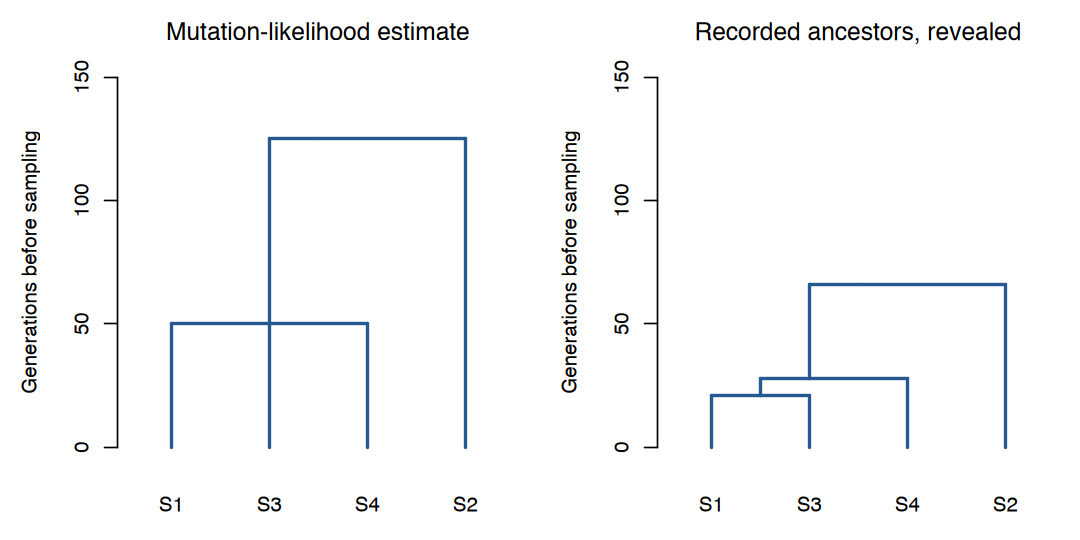

In [11]:
drawFigure("p6_tree_time_inference", function() {
    par(mfrow = c(1, 2), mar = c(3, 4.5, 2.4, .8), bg = "white")
    estimated <- setNames(age_table$estimate_min, age_table$clade)
    maximum <- max(c(estimated, truth3$ages)) * 1.2
    drawTree(consensus3$tree, estimated, maximum, "Mutation-likelihood estimate")
    drawTree(truth3$tree, truth3$ages, maximum, "Recorded ancestors, revealed")
})


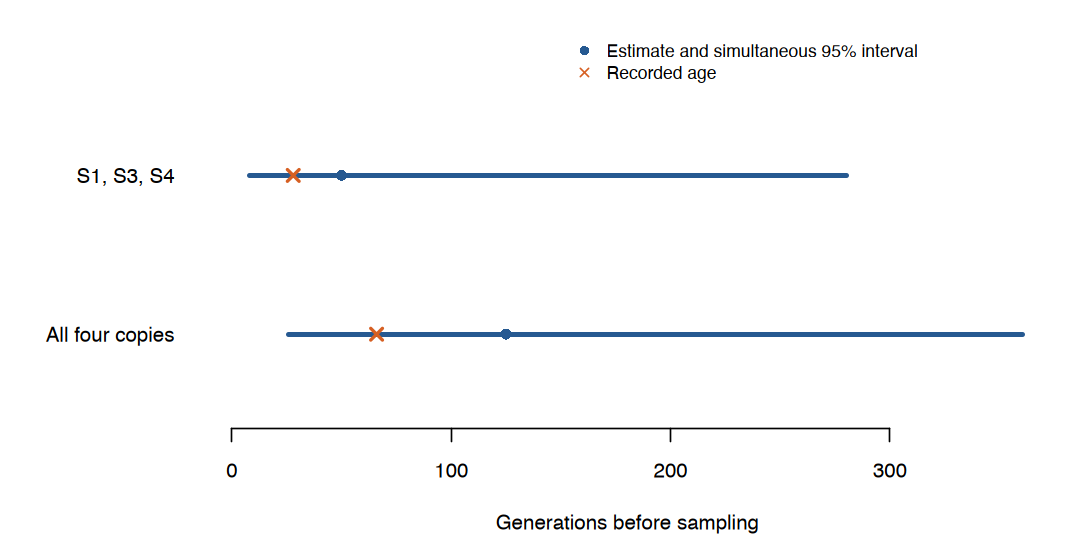

In [12]:
drawFigure("p6_ancestral_time_intervals", function() {
    par(mar = c(4.3, 7.7, 1.3, 1), bg = "white")
    table <- age_table[2:1, ]
    plot(NA, xlim = range(c(0, table$upper)), ylim = c(.5, 2.8), yaxt = "n",
         xlab = "Generations before sampling", ylab = "", bty = "n")
    axis(2, 1:2, c("All four copies", "S1, S3, S4"), las = 1, tick = FALSE)
    segments(table$lower, 1:2, table$upper, 1:2, lwd = 3, col = blue)
    points(table$estimate_min, 1:2, pch = 16, col = blue)
    points(table$recorded_age, 1:2, pch = 4, cex = 1.2, lwd = 2, col = orange)
    legend("topright", c("Estimate and simultaneous 95% interval", "Recorded age"),
           col = c(blue, orange), pch = c(16, 4), bty = "n", y.intersp = 1.8, cex = .85)
}, height = 3.1)


In [13]:
record4 <- pgRecordAncestry(rep(80L, 61), 1000, n = 12L, map_length = .03,
                            ancestry_seed = pgRegionSeed(818900L, 1L))
mutation4 <- pgMutateAncestry(record4, mu, pgRegionSeed(918900L, 1L, TRUE))
stopifnot(identical(mutation4$haplotypes, unname(linked$haplotypes)),
          identical(mutation4$positions_bp, positions4),
          identical(frozen_linked, serialize(list(constraints4, local_consensus), NULL)))
local_truth4 <- lapply(pgCompressTrees(record4), recordedSubset)
local_keys4 <- vapply(local_truth4, function(x) paste(sort(names(x$ages)), collapse = ";"),
                     character(1))
recorded_changes4 <- sum(local_keys4[-1] != head(local_keys4, -1))
cat("Minimum changes required by the four observed copies:", constraints4$minimum_changes,
    "\nRecorded topology changes for those copies:", recorded_changes4, "\n")


Minimum changes required by the four observed copies: 2 
Recorded topology changes for those copies: 9 


## How much does a short sequence leave unresolved?

Repeat the same demographic design with 60 predeclared, independent seed pairs.
Each run generates full forward parent maps and 12 sampled sequences. The inference
receives only the first four sequences, the analyzed length and mutation rate.
Evaluate clade constraints and time intervals afterward against that run's record.
Keep every replicate, including zero-information and unresolved cases.
A sequence with no mutations can give a zero-age boundary estimate and still
have a positive upper bound. This is a limit of the mutation likelihood.


In [14]:
recovery <- do.call(rbind, lapply(1:60, function(i) {
    aseed <- pgRegionSeed(11814900L, i)
    mseed <- pgRegionSeed(12814900L, i, TRUE)
    record <- pgRecordAncestry(sizes3, L, n = 12L, ancestry_seed = aseed)
    mutation <- pgMutateAncestry(record, mu, mseed)
    G <- mutation$haplotypes[1:4, , drop = FALSE]
    fit <- ptiFitAges(G, mu, L)
    intervals <- ptiPairIntervals(G, mu, L)
    truth <- recordedSubset(pgCompressTree(record))
    root <- ptiCladeInterval(intervals, 1:4)
    clades_ok <- all(vapply(fit$consensus$supported_clades, function(c)
        ptiKey(c) %in% names(truth$ages), logical(1)))
    root_estimate <- fit$node_ages$estimate_min[fit$node_ages$clade == "1,2,3,4"]
    data.frame(replicate = i, compatible = fit$consensus$compatible_count,
        estimated_root = root_estimate, recorded_root = unname(truth$ages["1,2,3,4"]),
        covered = root$lower <= truth$ages["1,2,3,4"] &&
                  truth$ages["1,2,3,4"] <= root$upper, clades_valid = clades_ok,
        ancestry_seed = aseed, mutation_seed = mseed)
}))
stopifnot(all(recovery$clades_valid), !anyDuplicated(c(recovery$ancestry_seed,
                                                     recovery$mutation_seed)))
print(data.frame(replicates = nrow(recovery), unique_tree = sum(recovery$compatible == 1),
    unresolved = sum(recovery$compatible > 1), root_intervals_cover = sum(recovery$covered)))


  replicates unique_tree unresolved root_intervals_cover
1         60          21         39                   58


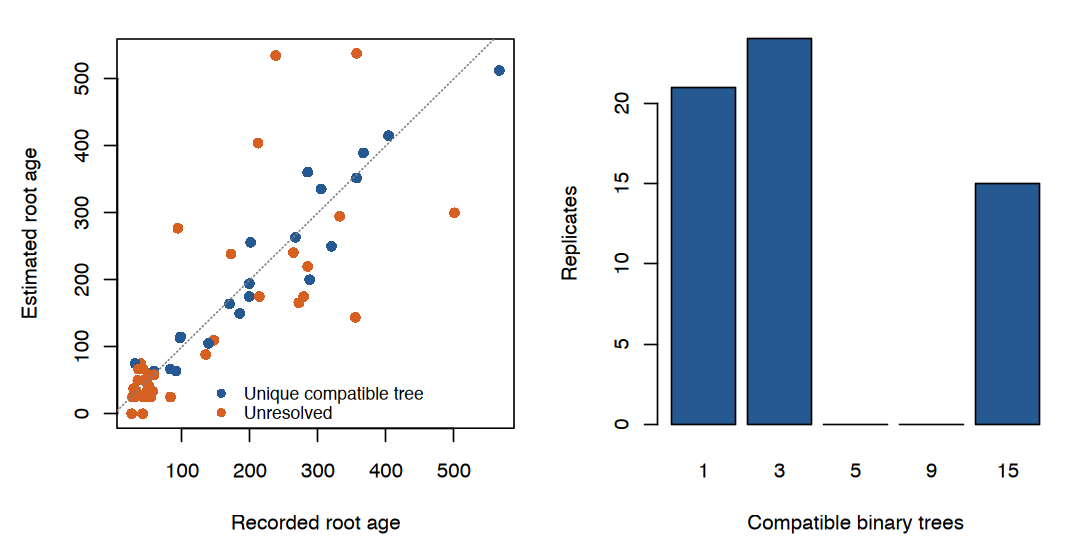

In [15]:
drawFigure("p6_tree_recovery", function() {
    par(mfrow = c(1, 2), mar = c(4.3, 4.5, 1.5, 1), bg = "white")
    plot(recovery$recorded_root, recovery$estimated_root, pch = 16,
         col = ifelse(recovery$compatible == 1, blue, orange),
         xlab = "Recorded root age", ylab = "Estimated root age")
    abline(0, 1, lty = 3, col = "gray50")
    legend("bottomright", c("Unique compatible tree", "Unresolved"),
           col = c(blue, orange), pch = 16, bty = "n", cex = .85, y.intersp = 1.6)
    barplot(table(factor(recovery$compatible, levels = c(1, 3, 5, 9, 15))),
            col = blue, xlab = "Compatible binary trees", ylab = "Replicates")
})


## A specified change of local genealogy

Specify a 100-kb region whose left tree contains clade {1,2} and right tree
contains clade {1,3}. Their root ages are 800 generations; the prescribed
change is at 50 kb. Conditional Poisson mutations generate the sequences.
Inference receives the sequences, positions and mutation rate.

Under a single-change model, the breakpoint must separate every pair of
incompatible carrier sets. Intersect those intervals, then fit local node
ages in the first and last quarters, fixed before consulting the truth.
Red dashed lines show the prescribed breakpoint and root age after fitting.


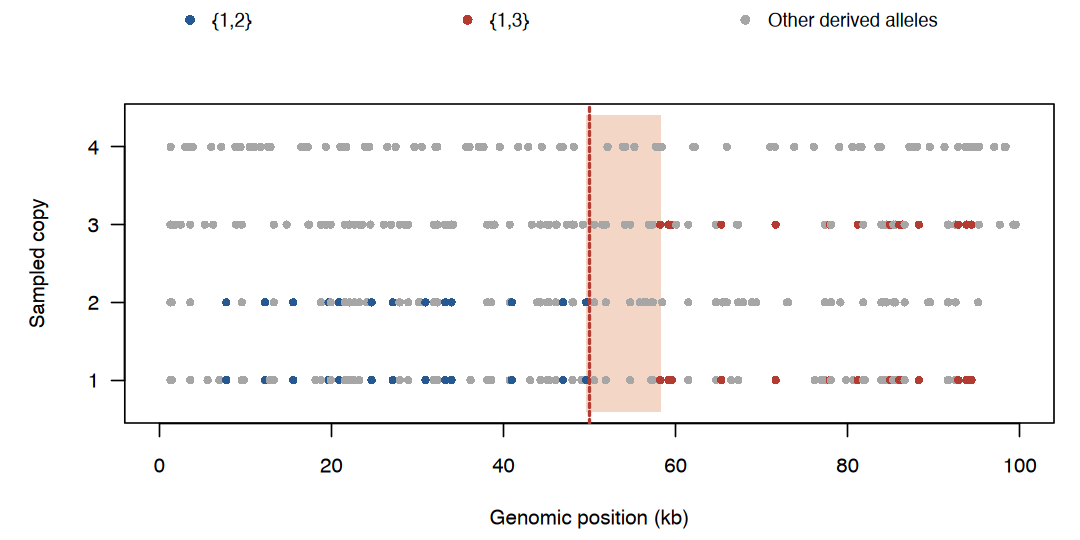

        window estimated_TMRCA generating_TMRCA
 first_quarter        932.7041              800
  last_quarter        900.0975              800


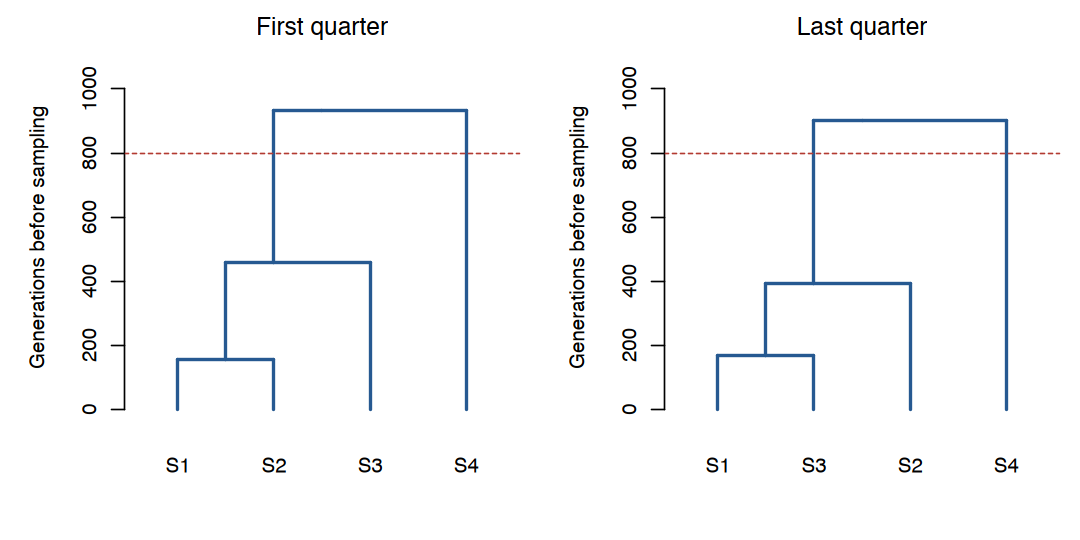

In [16]:
specified <- specifiedLocalTreeExample()
local_observed <- specified$observed
local_mu <- specified$calibration$mutationRate
constraints <- ptiLinkedConstraints(local_observed$haplotypes, local_observed$positions)
change_interval <- c(max(constraints$witnesses$left), min(constraints$witnesses$right))
windows <- list(first_quarter = c(0, 25000), last_quarter = c(75000, 100000))
local_fits <- lapply(windows, function(window) {
    keep <- local_observed$positions >= window[1] & local_observed$positions < window[2]
    ptiFitAges(local_observed$haplotypes[, keep, drop = FALSE], local_mu, diff(window))
})
stopifnot(constraints$minimum_changes == 1L,
    all(vapply(local_fits, function(f) f$consensus$compatible_count == 1L, TRUE)))
frozen_local <- serialize(list(change_interval, local_fits), NULL)

drawFigure("local_tree_change", function() {
    par(mar = c(4.5, 4.8, 4, 1), bg = "white")
    G <- local_observed$haplotypes
    pos <- local_observed$positions / 1000
    plot(NA, xlim = c(0, 100), ylim = c(.6, 4.4),
         xlab = "Genomic position (kb)", ylab = "Sampled copy", yaxt = "n")
    axis(2, 1:4, 1:4, las = 1)
    rect(change_interval[1] / 1000, .6, change_interval[2] / 1000, 4.4,
         col = adjustcolor("#D65F22", .25), border = NA)
    for (j in seq_len(ncol(G))) {
        carriers <- unname(which(G[, j] == 1))
        color <- if (identical(carriers, 1:2)) blue else
            if (identical(carriers, c(1L, 3L))) "#B33B32" else "gray65"
        points(rep(pos[j], length(carriers)), carriers, pch = 16, col = color, cex = .75)
    }
    abline(v = specified$truth$breakpoint / 1000, lty = 2, lwd = 2, col = "#B33B32")
    legend("top", inset = c(0, -.30), xpd = NA, horiz = TRUE,
        c("{1,2}", "{1,3}", "Other derived alleles"),
        col = c(blue, "#B33B32", "gray65"), pch = 16, bty = "n", cex = .9)
}, height = 4)

drawFigure("inferred_local_tree_times", function() {
    par(mfrow = c(1, 2), mar = c(4.5, 4.8, 2, .8), bg = "white")
    maximum <- max(specified$truth$TMRCA,
        unlist(lapply(local_fits, function(f) f$node_ages$estimate_min))) * 1.15
    for (j in seq_along(local_fits)) {
        fit <- local_fits[[j]]
        ages <- setNames(fit$node_ages$estimate_min, fit$node_ages$clade)
        drawTree(fit$consensus$trees[[1L]], ages, maximum,
                  title = c("First quarter", "Last quarter")[j])
        abline(h = specified$truth$TMRCA, lty = 2, col = "#B33B32")
    }
}, width = 7.5, height = 3.6)
stopifnot(identical(frozen_local, serialize(list(change_interval, local_fits), NULL)),
    change_interval[1] < specified$truth$breakpoint,
    change_interval[2] > specified$truth$breakpoint)
print(data.frame(window = names(windows),
    estimated_TMRCA = vapply(local_fits, function(f)
        f$node_ages$estimate_min[f$node_ages$clade == "1,2,3,4"], 0),
    generating_TMRCA = specified$truth$TMRCA), row.names = FALSE)


Seven variable sites support a clade but leave its internal split unresolved.
The mutation clock gives noisy ancestral ages. The linked control's conflicting carrier sets require
at least two local-tree changes, while many partitions remain compatible with those sites.
More sequence evidence can narrow these possibilities; an inferred node age dates
shared ancestry, and a mutation on its branch can be younger than the parent node.

Sources: [Pritchard](https://web.stanford.edu/group/pritchardlab/HGbook.html),
Sections 2.2–2.3 and 3.3; Gorroochurn Notes, Sections 8.11–8.13.
Enumeration, mutation-likelihood fitting and simultaneous intervals here are small
base-R implementations of these models, not runs of ARGweaver, Relate or SINGER.


## A specified-tree calculation

Suppose copies 1 and 2 share an internal branch. Put one mutation on that branch
and one on each terminal branch. This gives five segregating sites, four singletons
and one doubleton. These constructed sites are separate from both sequence controls.


In [17]:
par(mfrow = c(1, 1), mar = c(4.5, 4.5, 1, .8), bg = "white")
# Apply the background on the next plot as well: kernels may open a new
# graphics device between cells. The original calculation cells stay intact.
setHook("before.plot.new", function() par(bg = "white"), action = "append")


In [18]:
carriers <- list(c(1, 2), 1, 2, 3, 4)
G <- matrix(0L, nrow = 4, ncol = length(carriers))
for (site in seq_along(carriers)) G[carriers[[site]], site] <- 1L
rownames(G) <- paste0('copy ', 1:4)
colnames(G) <- paste0('site ', 1:5)
G
stopifnot(identical(as.integer(colSums(G)), c(2L, 1L, 1L, 1L, 1L)))


,site 1,site 2,site 3,site 4,site 5
copy 1,1,1,0,0,0
copy 2,1,0,1,0,0
copy 3,0,0,0,1,0
copy 4,0,0,0,0,1


Let $\xi_i$ count sites with $i$ derived copies. The same matrix gives $S$ and
$\pi_{\rm region}$, the average pairwise difference. Averaged over neutral constant-size
genealogies, $E(\xi_i)=\theta/i$; a single small tree can differ from that expectation.


S pi_region   theta_W 
 5.000000  2.666667  2.727273

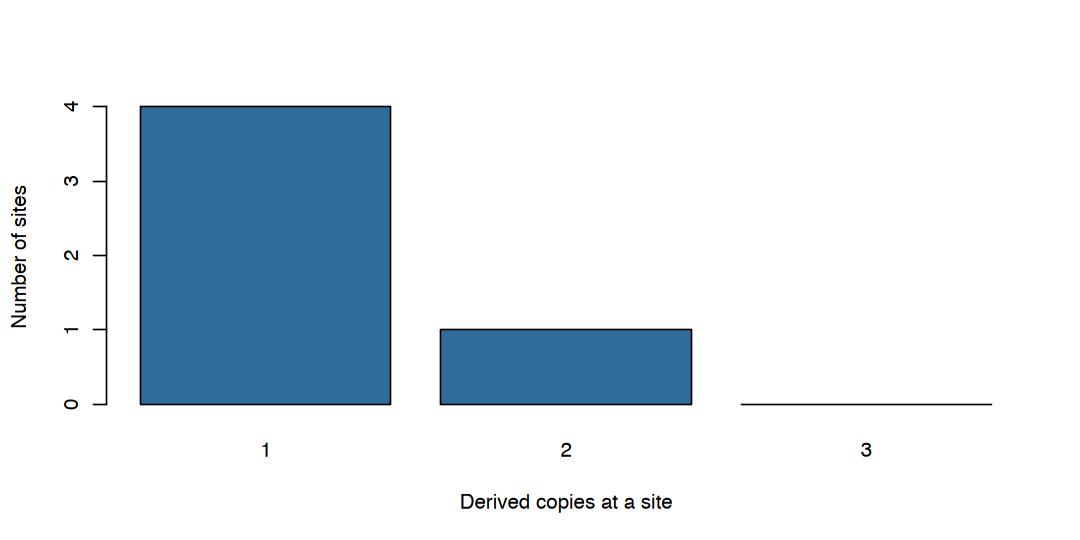

In [19]:
derived_count <- colSums(G)
S <- sum(derived_count > 0 & derived_count < nrow(G))
pi_region <- mean(as.vector(dist(G, method = 'manhattan')))
xi <- tabulate(derived_count, nbins = nrow(G) - 1)
theta_W <- S / sum(1 / seq_len(nrow(G) - 1))
stopifnot(S == 5, abs(pi_region - 8 / 3) < 1e-12)
barplot(xi, names.arg = seq_along(xi), col = '#306C9A',
        xlab = 'Derived copies at a site', ylab = 'Number of sites')
c(S = S, pi_region = pi_region, theta_W = theta_W)


The shared-branch mutation contributes more to pairwise diversity than a singleton;
both count once toward $S$. To check why an SFS alone cannot identify a labeled tree,
change only which samples carry the first site's derived allele.


In [20]:
G_control <- G
G_control[, 1] <- c(1, 0, 1, 0)
stopifnot(identical(colSums(G_control), colSums(G)),
          ptiKey(ptiConsensus(G)$supported_clades[[1]]) == "1,2",
          ptiKey(ptiConsensus(G_control)$supported_clades[[1]]) == "1,3")
cat("Same SFS; supported clade changes from {S1,S2} to {S1,S3}.\n")


Same SFS; supported clade changes from {S1,S2} to {S1,S3}.


## Recent growth and the singleton spectrum

In Pritchard's rapid-growth approximation, each sampled lineage gains
$g$ recent generations before any coalescence. Across $B$ independent
regions, each of length $L$,
$$E(\xi_i)=B\mu L\{4N_e/i+ng\,\mathbf{1}(i=1)\}.$
Counts above one copy inform ancestral size; excess singletons inform $g$.
The supplied example uses ancestral $N_e=80$, $g=40$, twelve copies and
48 regions. Fit a Poisson composite likelihood and resample whole regions
120 times for uncertainty. The plots compare constant size with this
specified extension; the bootstrap retains dependence among SFS bins.
Source: Pritchard, Sec. 2.2, pp. 99-100.


          parameter generating estimate    lower     upper
       ancestral_Ne         80 92.82742 77.31428 108.48882
 recent_generations         40 32.85961 24.05346  40.42018


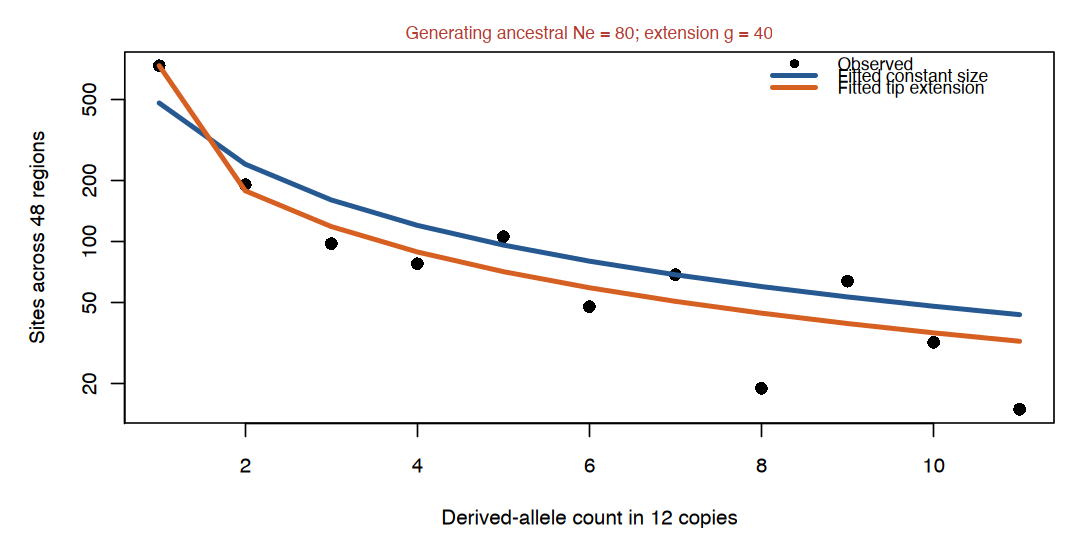

In [21]:
growth <- terminalExtensionExample()
print(data.frame(parameter = names(growth$fit$estimate),
    generating = c(growth$truth$Ne, growth$truth$extension),
    estimate = unname(growth$fit$estimate),
    lower = growth$interval[1, ], upper = growth$interval[2, ]), row.names = FALSE)
drawFigure("sfs_history_fit", function() {
    par(mar = c(4.5, 4.8, 2, 1), bg = "white")
    fit <- growth$fit
    plot(seq_along(fit$observed), fit$observed, pch = 16, cex = 1.2, log = "y",
         xlab = "Derived-allele count in 12 copies", ylab = "Sites across 48 regions",
         ylim = range(fit$observed, fit$expected, fit$constantExpected))
    lines(seq_along(fit$observed), fit$constantExpected, col = blue, lwd = 3)
    lines(seq_along(fit$observed), fit$expected, col = "#D65F22", lwd = 3)
    legend("topright", c("Observed", "Fitted constant size", "Fitted tip extension"),
           col = c("black", blue, "#D65F22"), pch = c(16, NA, NA),
           lty = c(NA, 1, 1), lwd = c(NA, 3, 3), bty = "n", cex = .85)
    mtext("Generating ancestral Ne = 80; extension g = 40", side = 3,
          line = .4, col = "#B33B32", cex = .85)
}, width = 7, height = 4)
